# Mecanismo de atención aplicado a series de tiempo
### Notebook 1 de 2 · Predicción de la temperatura mínima diaria

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RubyDayana/transformers-series-tiempo/blob/main/notebooks/01_Atencion_Series_Tiempo.ipynb)

- **Estudiante:** Ruby Dayana Cárdenas Gómez
- **Curso:** CADI Deep Learning Conceptos - Universidad de Cundinamarca
- **Docente:** Nidia Stella García Roa
- **Repositorio:** https://github.com/RubyDayana/transformers-series-tiempo

---

**Objetivo.** Implementar desde cero el mecanismo de atención de producto punto escalado
(Vaswani et al., 2017) y usarlo para predecir la temperatura del día siguiente a partir de los
30 días anteriores. Se compara una red LSTM tradicional con la misma LSTM más una capa de atención,
y se analiza **a qué días del pasado presta atención el modelo**.

**Contenido**
1. Librerías y configuración
2. Datos: carga, exploración y preprocesamiento
3. El mecanismo de atención paso a paso
4. Modelos: LSTM y LSTM + atención
5. Entrenamiento
6. Evaluación en el conjunto de prueba (1990)
7. Interpretación de los pesos de atención
8. Análisis y conclusiones

In [1]:
# ==============================================================================
# 1. Librerías, semilla y dispositivo
# ==============================================================================
import os, math, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
def fijar_semilla(s=SEED):
    """Fija las semillas para que los resultados se puedan repetir."""
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
fijar_semilla()

def n_parametros(m):
    """Número de parámetros entrenables de un modelo."""
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print(f"PyTorch {torch.__version__} | NumPy {np.__version__} | Pandas {pd.__version__}")
print(f"Dispositivo: {device.upper()}")

PyTorch 2.15.0+cu132 | NumPy 2.5.3 | Pandas 3.0.5
Dispositivo: CPU


## 2. Datos

Se usa la serie **Daily Minimum Temperatures in Melbourne** (Australian Bureau of Meteorology, 1981-1990):
3650 observaciones diarias en °C. Es una serie con **estacionalidad anual** marcada (verano austral en
enero, invierno en julio) y bastante ruido de un día a otro.

**Preprocesamiento aplicado**
- Partición **cronológica** (nunca aleatoria en series de tiempo): 1981-1988 entrenamiento, 1989 validación, 1990 prueba.
- Normalización *z-score* con la media y la desviación del entrenamiento.
- **Ventanas deslizantes**: cada ejemplo son los 30 días anteriores (entrada) y la temperatura del día siguiente (objetivo).

In [2]:
# ==============================================================================
# 2. Carga de datos: temperatura mínima diaria en Melbourne (1981-1990)
# ==============================================================================
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
LOCAL = "../data/daily-min-temperatures.csv"           # copia incluida en el repositorio

df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL, parse_dates=["Date"])
# Algunas versiones del archivo traen valores como "?0.2": se limpian por seguridad
df["Temp"] = pd.to_numeric(df["Temp"].astype(str).str.replace("?", "", regex=False))
df = df.sort_values("Date").reset_index(drop=True)

print(f"Registros: {len(df)} | Desde {df.Date.min().date()} hasta {df.Date.max().date()}")
print(f"Valores nulos: {df.Temp.isna().sum()}")
display(df.head())
display(df.Temp.describe().round(2).to_frame().T)

Registros: 3650 | Desde 1981-01-01 hasta 1990-12-31
Valores nulos: 0


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


,count,mean,std,min,25%,50%,75%,max
Temp,3650.0,11.18,4.07,0.0,8.3,11.0,14.0,26.3


In [3]:
# ==============================================================================
# 3. Partición cronológica, normalización y ventanas deslizantes
# ==============================================================================
LOOKBACK = 30          # días de historia que ve el modelo
serie = df.Temp.values.astype(np.float32)
fechas = df.Date.values

fin_train = int((df.Date < "1989-01-01").sum())   # 1981-1988 → entrenamiento
fin_val   = int((df.Date < "1990-01-01").sum())   # 1989      → validación
fin_test  = len(df)                               # 1990      → prueba

# La media y la desviación se calculan SOLO con entrenamiento (evita fuga de información)
MU, SD = serie[:fin_train].mean(), serie[:fin_train].std()
z = (serie - MU) / SD

def crear_ventanas(z, inicio, fin, lookback=LOOKBACK):
    """X[i] = 30 días anteriores al día t, y[i] = temperatura del día t."""
    X, y, idx = [], [], []
    for t in range(max(inicio, lookback), fin):
        X.append(z[t - lookback:t]); y.append(z[t]); idx.append(t)
    return (torch.tensor(np.array(X)), torch.tensor(np.array(y)), np.array(idx))

Xtr, ytr, itr = crear_ventanas(z, 0, fin_train)
Xva, yva, iva = crear_ventanas(z, fin_train, fin_val)
Xte, yte, ite = crear_ventanas(z, fin_val, fin_test)
print(f"Media train = {MU:.2f} °C | Desv. train = {SD:.2f} °C")
print(f"Ventanas → train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} | test {tuple(Xte.shape)}")

Media train = 11.11 °C | Desv. train = 4.06 °C
Ventanas → train (2890, 30) | val (365, 30) | test (365, 30)


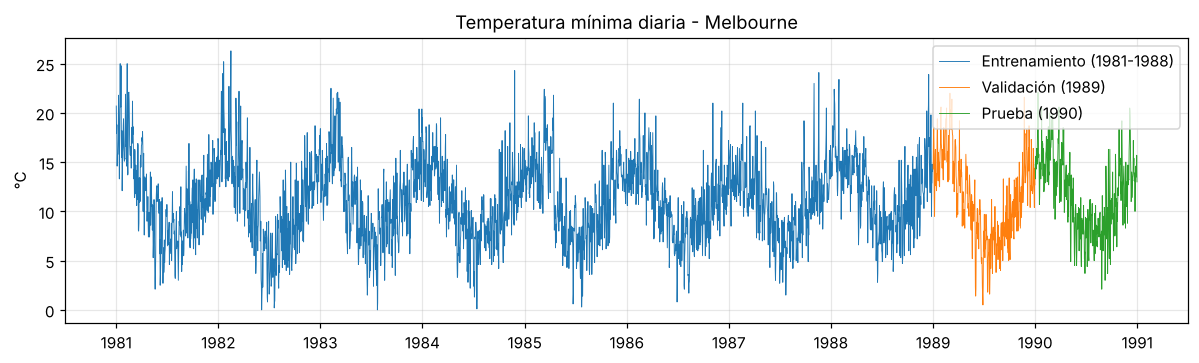

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(df.Date[:fin_train], serie[:fin_train], lw=.6, label="Entrenamiento (1981-1988)")
ax.plot(df.Date[fin_train:fin_val], serie[fin_train:fin_val], lw=.6, label="Validación (1989)")
ax.plot(df.Date[fin_val:], serie[fin_val:], lw=.6, label="Prueba (1990)")
ax.set_title("Temperatura mínima diaria - Melbourne"); ax.set_ylabel("°C"); ax.legend(loc="upper right")
plt.tight_layout(); os.makedirs("figuras", exist_ok=True); plt.savefig("figuras/serie.png", dpi=150); plt.show()

## 3. El mecanismo de atención paso a paso

La atención responde a la pregunta *"¿qué partes de la entrada son más útiles para lo que necesito ahora?"*.
Cada elemento se proyecta en tres vectores:

- **Query ($Q$)**: lo que se está buscando.
- **Key ($K$)**: la "etiqueta" de cada elemento, contra la que se compara la query.
- **Value ($V$)**: la información que se entrega si el elemento resulta relevante.

$$\text{Atención}(Q,K,V)=\text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

El producto $QK^\top$ mide la afinidad entre la query y cada key; dividir entre $\sqrt{d_k}$ evita que
la softmax se sature cuando la dimensión es grande; la softmax convierte las afinidades en pesos que suman 1;
y el resultado es un **promedio ponderado de los values**, el *vector de contexto*.

In [5]:
def atencion_producto_punto(Q, K, V, mascara=None):
    """Atención de producto punto escalado implementada a mano.
    Q: [B, Tq, d]   K: [B, Tk, d]   V: [B, Tk, dv]
    Devuelve: contexto [B, Tq, dv] y pesos [B, Tq, Tk]"""
    d_k = Q.size(-1)
    puntajes = Q @ K.transpose(-2, -1) / math.sqrt(d_k)       # 1) afinidad query-key escalada
    if mascara is not None:
        puntajes = puntajes.masked_fill(mascara == 0, float("-inf"))
    pesos = torch.softmax(puntajes, dim=-1)                   # 2) pesos que suman 1
    return pesos @ V, pesos                                   # 3) promedio ponderado de los values

# --- Ejemplo de juguete: 1 query y 4 elementos ---
Q = torch.tensor([[[1.0, 0.0]]])
K = torch.tensor([[[1.0, 0.0], [0.0, 1.0], [0.9, 0.1], [-1.0, 0.0]]])
V = torch.tensor([[[10.0], [20.0], [30.0], [40.0]]])
ctx, w = atencion_producto_punto(Q, K, V)
print("Pesos de atención:", w.squeeze().numpy().round(3))
print("Contexto:", ctx.item().__round__(3))

# --- Verificación contra la implementación oficial de PyTorch ---
Qr, Kr, Vr = torch.randn(8, 5, 16), torch.randn(8, 30, 16), torch.randn(8, 30, 16)
propio, _ = atencion_producto_punto(Qr, Kr, Vr)
oficial = F.scaled_dot_product_attention(Qr, Kr, Vr)
print(f"Diferencia máxima con F.scaled_dot_product_attention: {(propio - oficial).abs().max():.2e}")

Pesos de atención: [0.375 0.185 0.349 0.091]
Contexto: 21.567
Diferencia máxima con F.scaled_dot_product_attention: 2.98e-07


En el ejemplo, la query `[1, 0]` se parece al primer y al tercer elemento, por lo que reciben la mayor
parte del peso; el cuarto (`[-1, 0]`, dirección opuesta) casi no aporta. La diferencia con la función
oficial de PyTorch es del orden de $10^{-7}$ (error de redondeo), lo que confirma que la implementación es correcta.

### ¿Por qué escalar por $\sqrt{d_k}$?

In [6]:
for d in [4, 64, 512]:
    fijar_semilla()
    q, k = torch.randn(1, d), torch.randn(10, d)
    sin = torch.softmax(q @ k.T, -1).max().item()
    con = torch.softmax(q @ k.T / math.sqrt(d), -1).max().item()
    print(f"d_k = {d:3d} | peso máximo sin escalar = {sin:.3f} | con escalado = {con:.3f}")

d_k =   4 | peso máximo sin escalar = 0.240 | con escalado = 0.160
d_k =  64 | peso máximo sin escalar = 0.985 | con escalado = 0.377
d_k = 512 | peso máximo sin escalar = 0.999 | con escalado = 0.232


Sin el escalado, al crecer $d_k$ la softmax se vuelve casi *one-hot* (un elemento se lleva casi todo el peso),
y sus gradientes se hacen muy pequeños. Con el escalado la distribución se mantiene suave y el modelo puede aprender.

## 4. Modelos

| Modelo | Idea |
|---|---|
| **LSTM** | La LSTM recorre los 30 días y la predicción se hace solo con el **último estado oculto** $h_{30}$. Toda la historia debe "comprimirse" en ese vector. |
| **LSTM + Atención** | La LSTM produce un estado oculto por día $h_1,\dots,h_{30}$. El último estado actúa como **query**, todos los estados como **keys** y **values**. El vector de contexto se concatena con $h_{30}$ para predecir. |

Así la única diferencia entre ambos modelos es la capa de atención.

In [7]:
class LSTMSimple(nn.Module):
    """Red recurrente tradicional: predice con el último estado oculto."""
    def __init__(self, oculto=64):
        super().__init__()
        self.lstm = nn.LSTM(1, oculto, batch_first=True)
        self.salida = nn.Linear(oculto, 1)
    def forward(self, x):                      # x: [B, T]
        H, _ = self.lstm(x.unsqueeze(-1))      # H: [B, T, oculto]
        return self.salida(H[:, -1]).squeeze(-1), None


class AtencionTemporal(nn.Module):
    """Capa de atención: query = último estado, keys/values = todos los estados."""
    def __init__(self, d):
        super().__init__()
        self.Wq, self.Wk, self.Wv = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
    def forward(self, H):                      # H: [B, T, d]
        Q = self.Wq(H[:, -1:])                 # [B, 1, d]
        K, V = self.Wk(H), self.Wv(H)          # [B, T, d]
        contexto, pesos = atencion_producto_punto(Q, K, V)
        return contexto.squeeze(1), pesos.squeeze(1)   # [B, d], [B, T]


class LSTMAtencion(nn.Module):
    def __init__(self, oculto=64):
        super().__init__()
        self.lstm = nn.LSTM(1, oculto, batch_first=True)
        self.atencion = AtencionTemporal(oculto)
        self.salida = nn.Sequential(nn.Linear(2 * oculto, oculto), nn.ReLU(), nn.Linear(oculto, 1))
    def forward(self, x):
        H, _ = self.lstm(x.unsqueeze(-1))
        contexto, pesos = self.atencion(H)
        z = torch.cat([contexto, H[:, -1]], dim=-1)
        return self.salida(z).squeeze(-1), pesos

for m in [LSTMSimple(), LSTMAtencion()]:
    print(f"{m.__class__.__name__:13s} → {n_parametros(m):,} parámetros")

LSTMSimple    → 17,217 parámetros
LSTMAtencion  → 37,953 parámetros


## 5. Entrenamiento

Configuración: optimizador **Adam** (lr = 0,001), función de pérdida **MSE**, lotes de 64, máximo 60 épocas,
recorte de gradiente en 1,0 y **parada temprana** (si la pérdida de validación no mejora en 10 épocas se
detiene y se recuperan los mejores pesos).

In [8]:
# ==============================================================================
# Funciones de entrenamiento y evaluación (comunes a todos los modelos)
# Cada modelo devuelve (predicción, información_extra) → extra = pesos de atención o None
# ==============================================================================
def entrenar(modelo, nombre, epocas=60, lr=1e-3, bs=64, paciencia=10):
    fijar_semilla()
    modelo.to(device)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    perdida = nn.MSELoss()
    hist = {"train": [], "val": []}
    mejor, mejor_estado, sin_mejora = float("inf"), None, 0
    t0 = time.time()
    for ep in range(1, epocas + 1):
        modelo.train(); perm = torch.randperm(len(Xtr)); acum = 0.0
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]
            xb, yb = Xtr[b].to(device), ytr[b].to(device)
            opt.zero_grad()
            pred, _ = modelo(xb)
            loss = perdida(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step()
            acum += loss.item() * len(b)
        hist["train"].append(acum / len(Xtr))
        modelo.eval()
        with torch.no_grad():
            pv, _ = modelo(Xva.to(device))
            lv = perdida(pv, yva.to(device)).item()
        hist["val"].append(lv)
        if lv < mejor - 1e-5:
            mejor, sin_mejora = lv, 0
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
        if ep == 1 or ep % 10 == 0:
            print(f"[{nombre}] época {ep:3d} | MSE train {hist['train'][-1]:.4f} | MSE val {lv:.4f}")
        if sin_mejora >= paciencia:
            print(f"[{nombre}] parada temprana en la época {ep} (mejor val = {mejor:.4f})")
            break
    modelo.load_state_dict(mejor_estado)
    seg = time.time() - t0
    print(f"[{nombre}] tiempo de entrenamiento: {seg:.1f} s")
    return hist, seg

@torch.no_grad()
def predecir(modelo, X):
    """Predicción en °C (se deshace la normalización)."""
    modelo.eval()
    pred, extra = modelo(X.to(device))
    return pred.cpu().numpy() * SD + MU, extra

def metricas(real, pred):
    err = pred - real
    return {"MAE (°C)": np.abs(err).mean(), "RMSE (°C)": np.sqrt((err ** 2).mean()),
            "R²": 1 - (err ** 2).sum() / ((real - real.mean()) ** 2).sum()}

y_real_test = yte.numpy() * SD + MU
# Línea base ingenua (persistencia): mañana = hoy
pred_persist = Xte[:, -1].numpy() * SD + MU
print("Persistencia:", {k: round(float(v), 3) for k, v in metricas(y_real_test, pred_persist).items()})

Persistencia: {'MAE (°C)': 2.025, 'RMSE (°C)': 2.582, 'R²': 0.552}


In [9]:
fijar_semilla(); lstm = LSTMSimple()
hist_lstm, t_lstm = entrenar(lstm, "LSTM")
print()
fijar_semilla(); lstm_att = LSTMAtencion()
hist_att, t_att = entrenar(lstm_att, "LSTM+Atención")

[LSTM] época   1 | MSE train 0.6495 | MSE val 0.4106


[LSTM] época  10 | MSE train 0.3688 | MSE val 0.2831


[LSTM] época  20 | MSE train 0.3635 | MSE val 0.2871


[LSTM] época  30 | MSE train 0.3610 | MSE val 0.2784


[LSTM] época  40 | MSE train 0.3592 | MSE val 0.2764


[LSTM] época  50 | MSE train 0.3602 | MSE val 0.2753


... (4 outputs left out)

[LSTM+Atención] época  30 | MSE train 0.3591 | MSE val 0.2750


[LSTM+Atención] época  40 | MSE train 0.3557 | MSE val 0.2709


[LSTM+Atención] época  50 | MSE train 0.3557 | MSE val 0.2697


[LSTM+Atención] época  60 | MSE train 0.3497 | MSE val 0.2714
[LSTM+Atención] tiempo de entrenamiento: 17.9 s


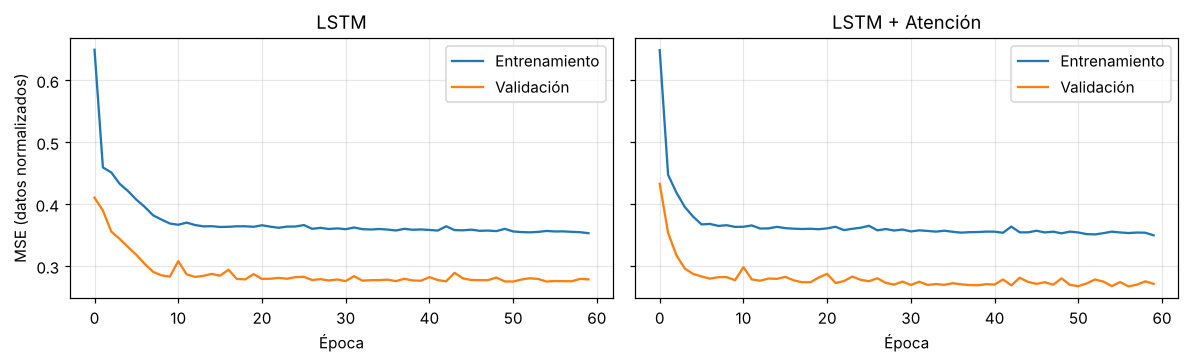

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, (h, n) in zip(ax, [(hist_lstm, "LSTM"), (hist_att, "LSTM + Atención")]):
    a.plot(h["train"], label="Entrenamiento"); a.plot(h["val"], label="Validación")
    a.set_title(n); a.set_xlabel("Época"); a.legend()
ax[0].set_ylabel("MSE (datos normalizados)")
plt.tight_layout(); plt.savefig("figuras/perdidas_atencion.png", dpi=150); plt.show()

## 6. Evaluación en el conjunto de prueba (año 1990)

In [11]:
p_lstm, _ = predecir(lstm, Xte)
p_att, pesos_test = predecir(lstm_att, Xte)
pesos_test = pesos_test.cpu().numpy()

tabla = pd.DataFrame({
    "Persistencia (mañana = hoy)": metricas(y_real_test, pred_persist),
    "LSTM": metricas(y_real_test, p_lstm),
    "LSTM + Atención": metricas(y_real_test, p_att),
}).T
tabla["Parámetros"] = [0, n_parametros(lstm), n_parametros(lstm_att)]
tabla["Tiempo (s)"] = [0, t_lstm, t_att]
tabla.round(3)

,MAE (°C),RMSE (°C),R²,Parámetros,Tiempo (s)
Persistencia (mañana = hoy),2.025,2.582,0.552,0,0.000
LSTM,1.722,2.244,0.661,17217,11.967
LSTM + Atención,1.694,2.211,0.671,37953,17.871


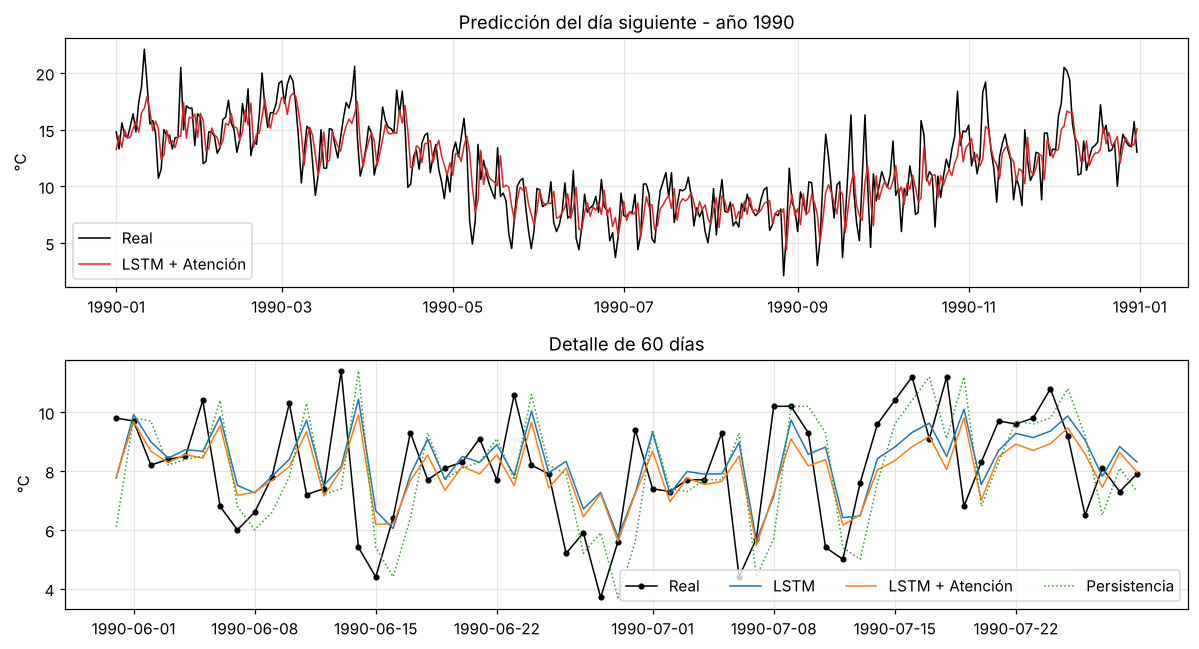

In [12]:
fechas_test = df.Date.values[ite]
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
ax[0].plot(fechas_test, y_real_test, color="k", lw=1, label="Real")
ax[0].plot(fechas_test, p_att, color="tab:red", lw=1, label="LSTM + Atención")
ax[0].set_title("Predicción del día siguiente - año 1990"); ax[0].set_ylabel("°C"); ax[0].legend()
z = slice(150, 210)   # zoom: dos meses de invierno
ax[1].plot(fechas_test[z], y_real_test[z], "k.-", lw=1, label="Real")
ax[1].plot(fechas_test[z], p_lstm[z], lw=1, label="LSTM")
ax[1].plot(fechas_test[z], p_att[z], lw=1, label="LSTM + Atención")
ax[1].plot(fechas_test[z], pred_persist[z], ":", lw=1, label="Persistencia")
ax[1].set_title("Detalle de 60 días"); ax[1].set_ylabel("°C"); ax[1].legend(ncol=4)
plt.tight_layout(); plt.savefig("figuras/predicciones_atencion.png", dpi=150); plt.show()

## 7. Interpretación de los pesos de atención

Una ventaja clave de la atención es que es **interpretable**: para cada predicción se puede ver cuánto
peso le dio el modelo a cada uno de los 30 días anteriores. El retraso 1 es "ayer" y el 30 es "hace un mes".

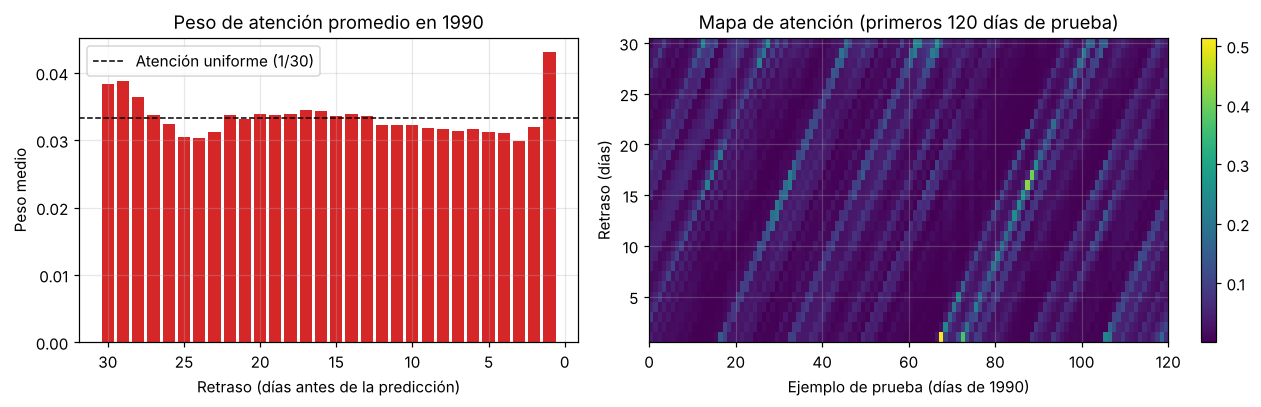

Retrasos con más atención: [(1, 0.043), (29, 0.039), (30, 0.038), (28, 0.036), (17, 0.034)]
Peso acumulado en la última semana (retrasos 1-7): 0.230
Entropía media de la atención: 3.074 (uniforme = 3.401)


In [13]:
retrasos = np.arange(LOOKBACK, 0, -1)          # posición 0 de la ventana = hace 30 días
peso_medio = pesos_test.mean(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].bar(retrasos, peso_medio, color="tab:red")
ax[0].axhline(1 / LOOKBACK, color="k", ls="--", lw=1, label="Atención uniforme (1/30)")
ax[0].set_xlabel("Retraso (días antes de la predicción)"); ax[0].set_ylabel("Peso medio")
ax[0].set_title("Peso de atención promedio en 1990"); ax[0].invert_xaxis(); ax[0].legend()
im = ax[1].imshow(pesos_test[:120].T, aspect="auto", cmap="viridis",
                  extent=[0, 120, 0.5, LOOKBACK + .5])
ax[1].set_xlabel("Ejemplo de prueba (días de 1990)"); ax[1].set_ylabel("Retraso (días)")
ax[1].set_title("Mapa de atención (primeros 120 días de prueba)")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.savefig("figuras/pesos_atencion.png", dpi=150); plt.show()

orden = np.argsort(-peso_medio)[:5]
print("Retrasos con más atención:", [(int(retrasos[i]), round(float(peso_medio[i]), 3)) for i in orden])
print(f"Peso acumulado en la última semana (retrasos 1-7): {peso_medio[-7:].sum():.3f}")
entropia = -(pesos_test * np.log(pesos_test + 1e-12)).sum(1).mean()
print(f"Entropía media de la atención: {entropia:.3f} (uniforme = {np.log(LOOKBACK):.3f})")

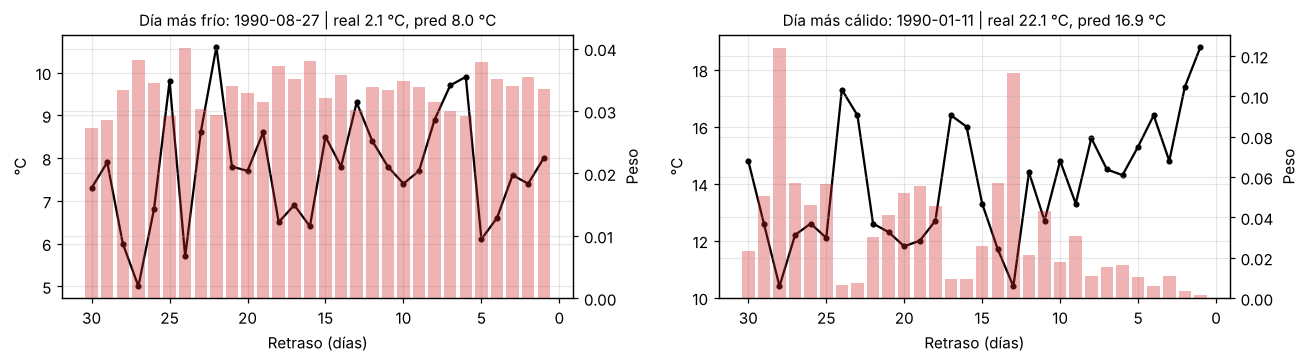

In [14]:
# Atención en días concretos: el día más frío y el más cálido de la prueba
frio, calido = int(np.argmin(y_real_test)), int(np.argmax(y_real_test))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for a, i, t in zip(ax, [frio, calido], ["Día más frío", "Día más cálido"]):
    hist_c = Xte[i].numpy() * SD + MU
    a2 = a.twinx()
    a.plot(retrasos, hist_c, "k.-", label="Temperatura de entrada")
    a2.bar(retrasos, pesos_test[i], alpha=.35, color="tab:red", label="Peso de atención")
    a.invert_xaxis(); a.set_xlabel("Retraso (días)"); a.set_ylabel("°C"); a2.set_ylabel("Peso")
    a.set_title(f"{t}: {pd.Timestamp(fechas_test[i]).date()} | real {y_real_test[i]:.1f} °C, "
                f"pred {p_att[i]:.1f} °C", fontsize=10)
plt.tight_layout(); plt.savefig("figuras/atencion_casos.png", dpi=150); plt.show()

## 8. Análisis y conclusiones

**Resultados en el año de prueba (1990)**

| Modelo | MAE (°C) | RMSE (°C) | R² |
|---|---|---|---|
| Persistencia (mañana = hoy) | 2,025 | 2,582 | 0,552 |
| LSTM | 1,722 | 2,244 | 0,661 |
| LSTM + Atención | **1,694** | **2,211** | **0,671** |

1. **Ambos modelos superan claramente a la línea base.** La persistencia se equivoca en promedio 2,0 °C; la LSTM con atención baja el error a 1,69 °C (16 % menos). La línea base es importante: sin ella no sabríamos si el modelo aprendió algo útil.
2. **La atención mejora a la LSTM, pero poco** (MAE de 1,722 a 1,694 °C). En pronóstico de un día, la mayor parte de la información está en los últimos días, y una LSTM ya la conserva bien. La atención aporta más cuando las dependencias son largas. Además, el modelo con atención tiene más del doble de parámetros (37 953 frente a 17 217), así que parte de la mejora puede deberse al tamaño y no solo a la atención.
3. **La atención es interpretable.** El retraso con más peso es *ayer* (0,043, por encima del uniforme 0,033), seguido por los días 28-30 de la ventana, que sirven como referencia del nivel del mes anterior. La entropía media (3,07 frente a 3,40 de la distribución uniforme) muestra que el modelo sí elige, aunque de forma suave.
4. **Atención basada en contenido.** En el mapa de atención aparecen franjas diagonales: cuando entra a la ventana un día atípico, el modelo lo sigue mirando mientras ese día "envejece" dentro de la ventana. La atención no depende solo de la posición sino del valor.
5. **Limitación.** Los modelos suavizan los extremos: el día más cálido de 1990 (22,1 °C) se predijo en 16,9 °C. Con solo la temperatura pasada no se pueden anticipar cambios bruscos del clima (frentes, olas de calor); se necesitarían variables como presión, viento o nubosidad.

**Conclusión.** El mecanismo de atención, implementado desde cero y verificado contra PyTorch, permitió que el modelo combine de forma ponderada los 30 días de historia y, sobre todo, permitió **ver** qué días usa para predecir. La mejora en exactitud fue modesta porque el problema es de horizonte corto y muy ruidoso.

*Nota: en Colab los números pueden variar ligeramente por diferencias de hardware y versión de librerías.*